In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set seed for reproducibility
np.random.seed(42)
CREATE_DATA = True
LOAD_CASE_STUDY = False

In [2]:
def create_synthetic_csv(num_clients=100, num_transactions=1000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"]):

    # Generate client-level data
    client_ids = np.arange(1, num_clients + 1)

    # Income: Should follow a right skewed distribution (log-normal)
    # Adjusting the income distribution to follow a log-normal distribution (right-skewed, long tail)
    mean_income = 10  # Log-normal mean
    sigma_income = 0.6  # Log-normal standard deviation

    # Generate income values (skewed distribution)
    client_incomes = np.random.lognormal(mean=mean_income, sigma=sigma_income, size=num_clients)
    client_incomes = np.interp(client_incomes, (client_incomes.min(), client_incomes.max()), (20000, 200000))

    #client_incomes = np.random.uniform(20000, 100000, size=num_clients)  # Continuous feature: income
    client_spending_categories = np.random.choice(client_categories, size=num_clients)  # Categorical feature

    # Map spending categories to a numerical effect (low = 0.8, mid = 1, high = 1.2)
    category_effects = {"low_spender": 0.8, "mid_spender": 1, "high_spender": 1.2}
    product_base_prices = {1: (10, 30), 2: (15, 50), 3: (5, 25)}

    data = []
    for _ in range(num_transactions):
        client = np.random.choice(client_ids)
        product = np.random.randint(1, num_products + 1)

        # Determine product base price range
        base_price_min, base_price_max = product_base_prices[product]
        mean_price = (base_price_min + base_price_max) / 2

        # Client attributes
        income = client_incomes[client - 1]
        category = client_spending_categories[client - 1]
        category_multiplier = category_effects[category]

        # Price is sampled randomly within the product's base range
        price = np.random.uniform(base_price_min, base_price_max)

        # Amount bought depends on price (inverse relation) and income (higher income buys more)
        base_demand = np.random.uniform(5, 20)  # Base demand per product
        income_factor = (income / 200000)  # Scaled income effect (higher income = more purchases)
        
        '''print("&"*50)
        print("price: ", price)
        print("mean_price: ", mean_price)
        print("price / mean_price: ", price / mean_price)
        print("(price / mean_price)**2: ", (price / mean_price)**2)
        print("(1 / (1 + (price / mean_price)**2)): ", (1 / (1 + (price / mean_price)**2)))
        print("&"*50)'''
        #amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (1 + (price / mean_price)**2))) + np.random.normal(0, 1))
        #amount_bought = max(0, (base_demand * category_multiplier * income_factor * (1 / (price / mean_price)**2)) + np.random.normal(0, 1))

        # Separate deterministic and stochastic parts
        deterministic_part = (base_demand * category_multiplier * income_factor * (1 / (price / mean_price)**2))

        # Stochastic part: noise based on price and income. Each row has a different noise. amount_boughtᵢ ~ Normal(μᵢ, σᵢ²)
        std_dev = 0.5 + 0.05 * (price / mean_price) + 0.1 * (1 - income_factor)
        noise = np.random.normal(0, std_dev)
        amount_bought = max(0, (deterministic_part + noise))

        data.append([client, product, price, amount_bought, income, category])

    # Create DataFrame
    df = pd.DataFrame(data, columns=["client_id", "product_id", "offered_price", "amount_bought", "income", "client_category"])
    df["amount_bought"] = df["amount_bought"].round().astype(int)
    df["amount_bought"] = df["amount_bought"].clip(lower=0)  # Ensure no negative values

    df_name_to_save = f"synthetic_dataset_{num_clients}clients_{num_transactions}trans.csv"
    df.to_csv("data/" + df_name_to_save, index=False)
    return df, df_name_to_save

def load_case_study_data():
    data = pd.read_csv('../DistCL_code/data_house_japan/data_clean.csv', index_col=0)
    data.index = pd.to_datetime(data.index)

    y = data['demand']
    X = data.drop(['demand'], axis=1, inplace=False)

    val_ind = X.index[(X.index >= pd.to_datetime('2018-11-01')) & (X.index < pd.to_datetime('2018-12-01'))]
    test_ind = X.index[X.index >= pd.to_datetime('2018-12-01')]

    return X, y, val_ind, test_ind


In [3]:
if CREATE_DATA:
    print("Creating synthetic data...")
    df, df_name = create_synthetic_csv(num_clients=10, num_transactions=10000, num_products=3, client_categories=["low_spender", "mid_spender", "high_spender"])

Creating synthetic data...


Loading synthetic data...


,client_id,product_id,offered_price,amount_bought,income,client_category
15,1,1,21.225544,4,78462.936812,low_spender
21,1,1,14.558703,6,78462.936812,low_spender
27,1,1,14.791238,4,78462.936812,low_spender
30,1,1,16.415601,4,78462.936812,low_spender
33,1,3,11.821327,3,78462.936812,low_spender


len(df): 981


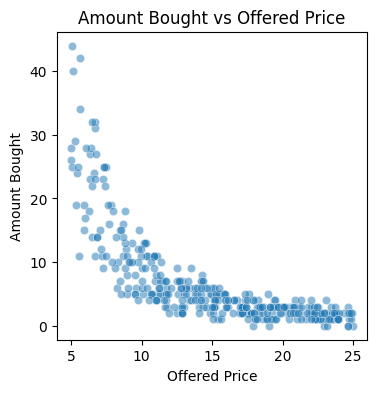

               offered_price  income  amount_bought
offered_price       1.000000     NaN      -0.533389
income                   NaN     NaN            NaN
amount_bought      -0.533389     NaN       1.000000


In [4]:
if LOAD_CASE_STUDY:
    print("Loading case study data...")
    X, y, val_ind, test_ind = load_case_study_data()
    display(X.head())
else:
    print("Loading synthetic data...")
    # Load the synthetic dataset
    df = pd.read_csv("data/synthetic_dataset_10clients_10000trans.csv")
    df = df[df['client_id'] == 1]  # Filter for client_id = 1
    display(df.head())
    print("len(df):", len(df))

    df_filtered = df[df['product_id'] == 3]

    plt.figure(figsize=(4, 4))
    sns.scatterplot(x=df_filtered["offered_price"], y=df_filtered["amount_bought"], alpha=0.5)
    plt.xlabel("Offered Price")
    plt.ylabel("Amount Bought")
    plt.title("Amount Bought vs Offered Price")
    plt.show()

    target = 'amount_bought'
    numerical_features = ['offered_price', 'income']
    categorical_features = ['client_category']

    correlation_matrix = df[numerical_features + [target]].corr()
    print(correlation_matrix)


In [5]:
import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

np.random.seed(42)
torch.manual_seed(1)

In [6]:
class AverageMeter(object):
    """Computes and stores the average and current value"""
    def __init__(self):
        self.reset()

    def reset(self):
        self.val = 0
        self.avg = 0
        self.sum = 0
        self.count = 0

    def update(self, val, n=1):
        self.val = val
        self.sum += val * n
        self.count += n
        self.avg = self.sum / self.count

In [7]:
# Model definition
class distModel(nn.Module):
    def __init__(self, input_size, hidden_layers, hidden_size, drop):
        super().__init__() # Call the parent class (nn.Module) constructor.
        self.input_size = input_size
        self.hidden_layers = hidden_layers
        self.hidden_size = hidden_size
        self.drop = drop

        # Define the input layer
        self.input_layer = nn.Linear(self.input_size, self.hidden_size)

        # Define the hidden layers
        self.hidden_layers = nn.ModuleList([nn.Linear(self.hidden_size, self.hidden_size) for _ in range(self.hidden_layers)])

        # Output mean Layer
        self.output_mean_layer = nn.Linear(self.hidden_size, 1)
        
        # Output var Layer
        self.output_sd_layer = nn.Linear(self.hidden_size, 1)

        # Define the activation function
        self.relu = nn.ReLU()

        # Define the dropout layer
        self.dropout = nn.Dropout(self.drop)

    def forward(self, x):
        # Define the forward pass
        x = self.relu(self.input_layer(x))
        for hidden_layer in self.hidden_layers:
            x = self.relu(hidden_layer(x))
            x = self.dropout(x)
        mean = self.output_mean_layer(x)
        sd = self.relu(self.output_sd_layer(x)) # Ensure variance is non-negative, can still be 0. ReLU is linear.
        #sd = self.relu(self.output_sd_layer(x)) + 1e-6 # Ensure variance is positive, can't be 0. ReLU is linear.
        #sd = self.output_sd_layer(x)
        return mean, sd


In [8]:
class PandasDataset(Dataset):
    def __init__(self, X, y=None, transform=None):
        self.X = X.values if isinstance(X, pd.DataFrame) else X
        self.y = y.values if isinstance(y, pd.Series) else y
        self.transform = transform

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x = torch.tensor(self.X[idx], dtype=torch.float32)
        if self.transform:
            x = self.transform(x)
        if self.y is not None:
            y = torch.tensor(self.y[idx], dtype=torch.float32)
            return x, y
        return x

In [9]:

# Define trainer class
device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")

class Trainer():
    torch.manual_seed(1)
    def __init__(self, X, y, model_config, training_config):
        self.X = X
        self.y = y

        self.model_config = model_config
        self.training_config = training_config

        # Definde the model
        self.model = distModel(input_size=self.X.shape[1], hidden_layers=self.model_config['hidden_layers'], hidden_size=self.model_config['hidden_size'], drop=self.model_config['drop']).to(device)

        # Define criterion: https://pytorch.org/docs/stable/generated/torch.nn.GaussianNLLLoss.html
        self.criterion = nn.GaussianNLLLoss()

    def create_data_partitions(self, create_test=True, test_size=0.2, val_size=0.1, random_state=42):
        '''
        Splits self.X and self.y into train, validation, and optionally test sets.

        Parameters:
        - create_test (bool): Whether to create a test set.
        - test_size (float): Proportion of data for the test set (if created).
        - val_size (float): Proportion of the training data for validation.
        - random_state (int): Random seed for reproducibility.

        Returns:
        - Dictionaries containing the partitions.
        '''
        X_train, X_temp, y_train, y_temp = train_test_split(self.X, self.y, 
                                                            test_size=(test_size + val_size) if create_test else val_size, 
                                                            random_state=random_state)
        
        self.X_train = X_train
        self.X_val = X_temp
        self.y_train = y_train
        self.y_temp = y_temp
        
        if create_test:
            X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, 
                                                            test_size=test_size / (test_size + val_size), 
                                                            random_state=random_state)
            self.X_val = X_val
            self.X_test = X_test
            self.y_val = y_val
            self.y_test = y_test
    
    def set_data_partitions(self, X_train, y_train, X_val, y_val, X_test=None, y_test=None):
        '''
        Sets the data partitions directly.

        Parameters:
        - X_train (pd.DataFrame): Training features.
        - y_train (pd.Series): Training target.
        - X_val (pd.DataFrame): Validation features.
        - y_val (pd.Series): Validation target.
        - X_test (pd.DataFrame, optional): Test features.
        - y_test (pd.Series, optional): Test target.
        '''
        self.X_train = X_train
        self.y_train = y_train
        self.X_val = X_val
        self.y_val = y_val

        if X_test is not None and y_test is not None:
            self.X_test = X_test
            self.y_test = y_test
            
    def train(self):
        torch.cuda.empty_cache()

        train_ds = PandasDataset(self.X_train, self.y_train)
        val_ds = PandasDataset(self.X_val, self.y_val)
        
        train_dl = DataLoader(train_ds, batch_size = self.training_config['batchsize'], shuffle=True)
        val_dl = DataLoader(val_ds, batch_size=len(val_ds)) # self.training_config['batchsize']?

        iters = self.training_config['iters']
        # Define optimizer: https://pytorch.org/docs/stable/generated/torch.optim.Adam.html
        optimizer = optim.Adam(self.model.parameters(), lr = self.training_config['lr'], weight_decay=self.training_config['wd'])

        best_loss = float('inf')
        for epoch in range(iters):
            ## Training
            self.model.train()
            self.train_loss = AverageMeter()
            for i, (x, y) in enumerate(train_dl):
                x, y = x.to(device), y.to(device)
                optimizer.zero_grad()
                mean, sd = self.model(x)
                #print("sd: ", len(sd))
                #mean, var = self.model(x)
                loss = self.criterion(mean, y, sd**2)
                #loss = self.criterion(mean, y, var)
                loss.backward()
                optimizer.step()
                self.train_loss.update(loss.item(), x.size(0))

            ## Validation
            self.model.eval()
            self.val_loss = AverageMeter()
            with torch.no_grad():
                for i, (x, y) in enumerate(val_dl):
                    x, y = x.to(device), y.to(device)
                    mean, sd = self.model(x)
                    loss = self.criterion(mean, y, sd**2)
                    self.val_loss.update(loss.item(), x.size(0))

            if self.val_loss.avg < best_loss:
                best_loss = self.val_loss.avg
                torch.save(self.model.state_dict(), 'best_model.pth')

            print(f'Epoch {epoch+1}/{iters} - Train Loss: {self.train_loss.avg:.4f}, Val Loss: {self.val_loss.avg:.4f}')

    def test(self):
        test_ds = PandasDataset(self.X_test, self.y_test)
        test_dl = DataLoader(test_ds, batch_size=len(test_ds)) # self.training_config['batchsize']?

        self.model.load_state_dict(torch.load('best_model.pth'))
        self.model.eval()

        ## Testing
        test_loss = AverageMeter()
        with torch.no_grad():
            for i, (x, y) in enumerate(test_dl):
                x, y = x.to(device), y.to(device)
                mean, sd = self.model(x)
                loss = self.criterion(mean, y, sd**2)
                test_loss.update(loss.item(), x.size(0))
        
        print(f'Test Loss: {test_loss.avg:.4f}')
    
    def predict(self, X, return_tensor=False):
        self.model.load_state_dict(torch.load('best_model.pth'))
        self.model.eval()

        pred_ds = PandasDataset(X)
        pred_dl = DataLoader(pred_ds, batch_size=len(pred_ds)) # self.training_config['batchsize']?

        with torch.no_grad():
            for i, x in enumerate(pred_dl):
                x = x.to(device)
                mean, sd = self.model(x)
            
            if return_tensor:
                mean_pred = mean
                sd_pred = sd
            else:
                mean_pred = mean.detach().cpu().numpy()
                sd_pred = sd.detach().cpu().numpy()
        
        return mean_pred, sd_pred

In [10]:
model_config = {
    'hidden_layers': 2,
    'hidden_size': 64,
    'drop': 0.2
    }

training_config = {
    'lr': 0.0001,
    'wd': 0.0001,
    'batchsize': 64,
    'iters': 500
    }



In [11]:
np.random.seed(42)
torch.manual_seed(1)
if LOAD_CASE_STUDY:
    print("Loading case study data...")
    trainer = Trainer(X, y, model_config, training_config)
    trainer.set_data_partitions(X_train=X[(~X.index.isin(val_ind)) & (~X.index.isin(test_ind))], y_train=y[(~y.index.isin(val_ind)) & (~y.index.isin(test_ind))], X_val=X[X.index.isin(val_ind)], y_val=y[y.index.isin(val_ind)], X_test=X[X.index.isin(test_ind)], y_test=y[y.index.isin(test_ind)])
else:
    print("Loading synthetic data...")
    trainer = Trainer(df[['offered_price', 'income']], df['amount_bought'], model_config=model_config, training_config=training_config)

    trainer.create_data_partitions()

print("X_train shape: ", trainer.X_train.shape)
print("X_val shape: ", trainer.X_val.shape)
print("X_test shape: ", trainer.X_test.shape)

trainer.train()

trainer.test()

Loading synthetic data...
X_train shape:  (686, 2)
X_val shape:  (98, 2)
X_test shape:  (197, 2)
Epoch 1/500 - Train Loss: 54259311672.0198, Val Loss: 8.2975
Epoch 2/500 - Train Loss: 51472028771.2611, Val Loss: 8.2061
Epoch 3/500 - Train Loss: 41766270925.1621, Val Loss: 8.1391
Epoch 4/500 - Train Loss: 26818334686.4230, Val Loss: 8.1139
Epoch 5/500 - Train Loss: 29081293228.8717, Val Loss: 8.0935
Epoch 6/500 - Train Loss: 23004572706.6412, Val Loss: 8.0814
Epoch 7/500 - Train Loss: 18814632511.5795, Val Loss: 8.0746
Epoch 8/500 - Train Loss: 9027987273.9757, Val Loss: 8.0672
Epoch 9/500 - Train Loss: 5731678671.3850, Val Loss: 8.0658
Epoch 10/500 - Train Loss: 7347490013.5967, Val Loss: 8.0620
Epoch 11/500 - Train Loss: 12463246095.6061, Val Loss: 8.0481
Epoch 12/500 - Train Loss: 13462859073.3289, Val Loss: 8.0533
Epoch 13/500 - Train Loss: 12447613510.2320, Val Loss: 8.0467
Epoch 14/500 - Train Loss: 6087224943.4694, Val Loss: 8.0253
Epoch 15/500 - Train Loss: 777462579.1481, Val L

In [12]:
mean_pred, sd_pred = trainer.predict(trainer.X_test)
mean_pred = np.squeeze(mean_pred)
sd_pred = np.squeeze(sd_pred)

def compute_nll(y_true, y_pred, y_std):
    """
    Computes Negative Log-Likelihood (NLL) for Gaussian distribution.
    
    Parameters:
    - y_true: True target values (numpy array).
    - y_pred: Predicted mean (numpy array).
    - y_std: Predicted standard deviation (numpy array).
    
    Returns:
    - Scalar NLL value
    """
    var = y_std ** 2  # Convert std deviation to variance
    nll = np.mean((y_true - y_pred) ** 2 / (2 * var) + 0.5 * np.log(2 * np.pi * var))
    return nll



nll = compute_nll(trainer.y_test, mean_pred, sd_pred)
print(f"Negative Log-Likelihood (NLL): {nll:.4f}")


Negative Log-Likelihood (NLL): 5.7100


In [13]:
y_train_tensor = torch.tensor(trainer.y_train.values, dtype=torch.float32).unsqueeze(1)  # shape [N, 1]

baseline_mean = torch.mean(y_train_tensor)
baseline_std = torch.std(y_train_tensor) # + 1e-6

# Repeat the values for every row
baseline_mean_preds = baseline_mean.repeat(y_train_tensor.shape[0], 1)
baseline_std_preds = baseline_std.repeat(y_train_tensor.shape[0], 1)

# Square std to get variance
baseline_var_preds = baseline_std_preds ** 2

criterion = nn.GaussianNLLLoss()
baseline_loss = criterion(baseline_mean_preds, y_train_tensor, baseline_var_preds)

print(f"Baseline Gaussian NLL Loss: {baseline_loss.item():.4f}")

pred_mean, pred_sd = trainer.predict(trainer.X_val, return_tensor=True)     # X_val: torch tensor of shape [N, D]
pred_var = pred_sd ** 2               # square to get variance
y_val_tensor = torch.tensor(trainer.y_val.values, dtype=torch.float32).unsqueeze(1).to(device)
model_loss = criterion(pred_mean, y_val_tensor, pred_var)

print(f"Model Gaussian NLL Loss: {model_loss.item():.4f}")

Baseline Gaussian NLL Loss: 2.1848
Model Gaussian NLL Loss: 4.7912


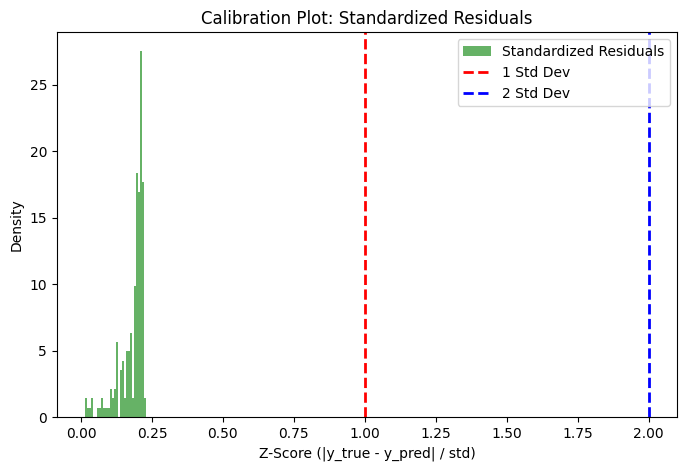

In [14]:
def plot_calibration(y_true, y_pred, y_std):
    """
    Creates a histogram of standardized residuals (Z-scores) to check uncertainty calibration.
    
    Parameters:
    - y_true: True target values (numpy array).
    - y_pred: Predicted mean (numpy array).
    - y_std: Predicted standard deviation (numpy array).
    
    Returns:
    - Calibration plot
    """
    z_scores = np.abs(y_true - y_pred) / y_std  # Standardized residuals

    plt.figure(figsize=(8, 5))
    plt.hist(z_scores, bins=30, density=True, alpha=0.6, color='g', label='Standardized Residuals')

    # Reference lines at 1σ and 2σ
    plt.axvline(1, color='r', linestyle='dashed', linewidth=2, label='1 Std Dev')
    plt.axvline(2, color='b', linestyle='dashed', linewidth=2, label='2 Std Dev')

    plt.xlabel('Z-Score (|y_true - y_pred| / std)')
    plt.ylabel('Density')
    plt.legend()
    plt.title('Calibration Plot: Standardized Residuals')
    plt.show()

plot_calibration(trainer.y_test, mean_pred, sd_pred)
